In [63]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Simplified EDA

First of all, we are going to load the dataset and perform exploratory data analysis, in order to get a good idea about what we are working with.

In [45]:
# First, we load the dataset, it is a PKL file.
df = pd.read_pickle("ecommerce_4.pkl")

First, we are going to see the dimensions, the types of variables present and the missing values they have, and whether there are constant columns

In [46]:
rows, cols = df.shape
print(f"The dataset has {rows} rows and {cols} variables\n")

# Let's list the variables we have
variables = pd.DataFrame({
    "Variable": df.columns,
    "Type": df.dtypes.values,
    "Null Values": df.isnull().sum().values,
    "Constant Column": (df.nunique() == 1).map({True: 'Yes', False: 'No'}).values
})

# Show the table
print(variables.to_string(index=False))

The dataset has 20240 rows and 26 variables

                Variable    Type  Null Values Constant Column
             Customer_ID  object            0              No
                     Age float64          974              No
                  Gender  object          612              No
          Credit_Balance float64         2245              No
          Signup_Quarter  object            0              No
        Membership_Years float64            0              No
             Logged_Freq float64            0              No
              Logged_Avg float64         1581              No
       Pages_Per_Session float64         1223              No
          Cart_Drop_Rate float64            0              No
          Wishlist_Items float64         1636              No
         Total_Purchases float64            0              No
     Average_Order_Value float64            0              No
   Days_without_Purchase float64         1222              No
     Discount_Usage_Rate 

Our dataset has 20240 instances and 26 features. The target variable, *Canceled*, appears to be numerical and discrete, but in fact we will see it is categorical, taking 0 or 1 as values. For the other variables we get a mix of numerical continuous, discrete and categorical. Talking about null values, we see that there are several features with some of them. The one with most is Media_Engage_Score, where approximately 10% of the total number of values is null. This quantity is not irrelevant, so preprocessing strategies like imputation will be needed. Finally, there are no constant columns.

Let's continue analyzing each type of variables. Starting with categorical variables, we must check which ones contain a high number of unique values. This is because in those cases an specific strategie should be followed in order to prevent overfitting and dimensional issues.

In [47]:
# Select categorical variables
categ_cols = df.select_dtypes("object").columns

# Cardinality 
cardinality = []

for c in categ_cols:
    cardinality.append({
        "Variable": c,
        "Cardinality": df[c].nunique()
    })

print("Cardinality of categorical values:\n ")
print(pd.DataFrame(cardinality).to_string(index=False))

Cardinality of categorical values:
 
      Variable  Cardinality
   Customer_ID        20240
        Gender            3
Signup_Quarter            4
       Country            8
          City           40


We see three different situations. First, *Gender* and *Signup_Quarter* exhibit low cardinality (3 and 4 respectively), so they are well suitable. In opposition, *Country* and *City* show high cardinality, especially the second one with 40 different values. Finally, obviously *Custiomer_ID* represents an identification, with one different value per costumer.

Talking about the target variable, *Canceled*, it is a binary variable indicating whether the customer has canceled the subscription (1) or remains active (0). Because of that, we are dealing with **Binary Classification Problem**. 

One of the first things we should study is if target variable is imbalanced, which means counting how much individuals we have from each class and compare them. For doing so, we begin transforming this variable into object type (it was int64).

In [48]:
df["Canceled"]=df["Canceled"].astype(object)

In [49]:
df["Canceled"].value_counts()

Canceled
0    10120
1    10120
Name: count, dtype: int64

We have exactly the same amount of instances for each class, so the target variable is perfectly balanced. As a consequence, metrics such as accuracy are reliable and sampling techniques to fix imbalance are not required.

### Univariated analysis

We have just analysed categorical features. Right now, let's study what happens with the numerical ones. For doing so, we use some statistics about their distributions.

In [65]:
df.select_dtypes("float64").describe().T

,count,mean,std,min,25%,50%,75%,max
Age,19266.0,37.272916,12.096028,5.00,28.2500,37.00,45.0000,200.000000
Credit_Balance,17995.0,1872.162990,1230.760333,0.00,933.0000,1789.00,2699.5000,6932.000000
Membership_Years,20240.0,2.982013,2.060633,0.10,1.4000,2.50,4.1000,10.000000
Logged_Freq,20240.0,10.880385,7.845472,0.00,5.0000,10.00,16.0000,46.000000
Logged_Avg,18659.0,26.557608,11.102648,1.00,18.3000,25.50,33.8000,75.600000
Pages_Per_Session,19017.0,8.359662,3.855650,1.00,5.6000,8.00,10.8000,23.200000
Cart_Drop_Rate,20240.0,59.153043,16.884008,0.00,47.9000,60.30,71.5000,141.390526
Wishlist_Items,18604.0,4.023436,3.188684,0.00,2.0000,3.00,6.0000,21.000000
Total_Purchases,20240.0,12.616324,7.216947,-13.00,7.8000,11.70,16.9000,128.700000
Average_Order_Value,20240.0,126.767626,183.148780,26.87,89.2000,115.95,149.1125,9487.427995


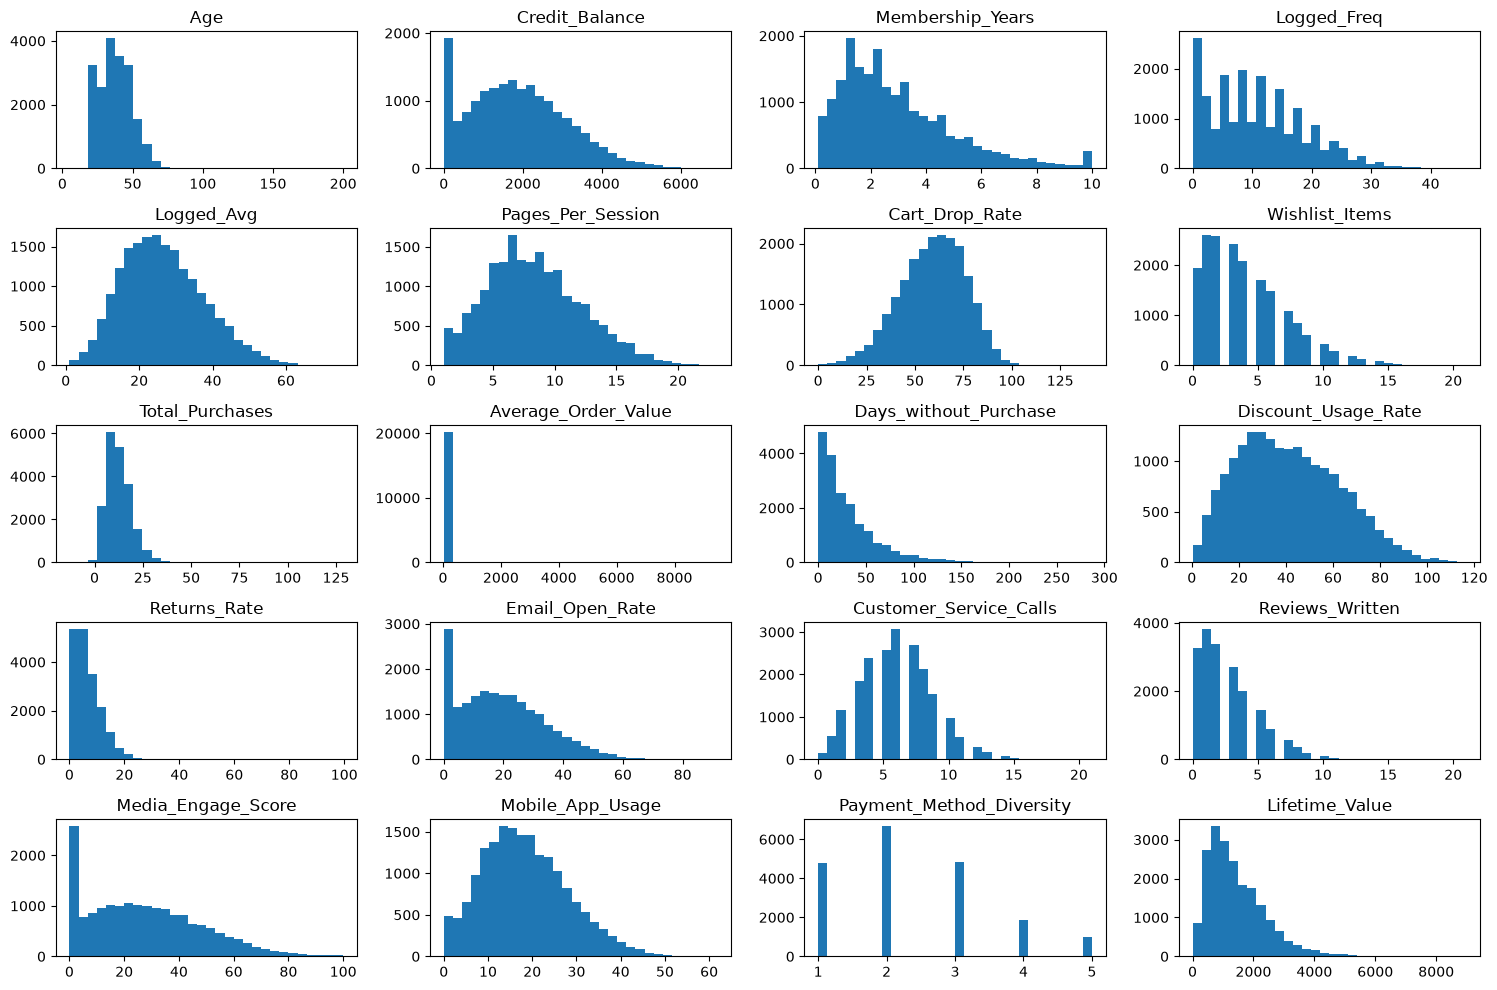

In [68]:
df.select_dtypes("float64").hist(figsize=(15, 10), bins=30, grid = False)
plt.tight_layout()
plt.show()


We can obtain several conclusions: 

- **Missing values:** as we said, most variables have missing values (dataset has 20240 rows). The highest rates are in *Media_Engage_Score* (~12%), *Credit_Balance* (~11%) and *Mobile_App_Usage* (~10%). Only *Membership_Years*, *Logged_Freq*, *Cart_Drop_Rate*, *Total_Purchases*, *Average_Order_Value* and *Lifetime_Value* are complete.
- **Invalid values:**
  - *Age* ranges from 5 to 200, which is impossible.
  - *Total_Purchases* has negative values (min −13).
  - *Cart_Drop_Rate* (max 141) and *Discount_Usage_Rate* (max 117) exceed 100%, if they are percentages.
- **Outliers:** *Average_Order_Value* is extreme (75th percentile 149, max 9487).
- **Skewness:**
  - Right-skewed: *Days_without_Purchase*, *Returns_Rate*, *Lifetime_Value*, *Credit_Balance*, *Email_Open_Rate* and *Membership_Years*.
  - Roughly symmetric: *Logged_Avg*, *Pages_Per_Session*, *Cart_Drop_Rate*, *Discount_Usage_Rate* and *Mobile_App_Usage*.
- **Unusual spikes:** *Credit_Balance*, *Email_Open_Rate* and *Media_Engage_Score* have a large spike at 0. *Membership_Years* has a spike at 10, which suggests a cap.
- **Discrete variables:** *Payment_Method_Diversity*, *Customer_Service_Calls*, *Wishlist_Items*, *Reviews_Written* and *Logged_Freq* are counts stored as floats.
- **Scales:** they differ widely across variables, so scaling is needed for distance-based models.